# Dixon model Analysis Notebook

This notebook is for analysis of the saved data collected using the main_dixon.ipynb notebook.

In [2]:
# analysis notebook
%reset -f

# autoreload imports
%load_ext autoreload
%autoreload 2

# import necessary libraries
import numpy as np
import pandas as pd
import csv
from pathlib import Path
from IPython.display import display
from datetime import datetime
from time import sleep

# Import scipy for analysis
from scipy.signal import find_peaks

# import matplotlib and plotly for interactive plots
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio
pio.renderers.default = "plotly_mimetype"

from Visualization.pop_plotting import plot_quad_dixon, plot_pop, pop_fit_plot
from Visualization.data_handling import load_data, sorted_sweep_files

## Testing model data saving and plotting code.

Reading data from Output_data/dixon_alpha_sweep_no_treatment/simu_data_dixon_alpha_715.72000000000003.csv


(<Figure size 1000x800 with 4 Axes>,
 array([[<Axes: title={'center': 'Populations over Time'}, xlabel='tau', ylabel='Population'>,
         <Axes: title={'center': 'Populations over Time'}, xlabel='tau', ylabel='Population'>],
        [<Axes: title={'center': 'Treatment over Time'}, xlabel='tau', ylabel='Dose'>,
         <Axes: title={'center': 'Fitness over Generations'}, xlabel='Generation', ylabel='Fitness'>]],
       dtype=object))

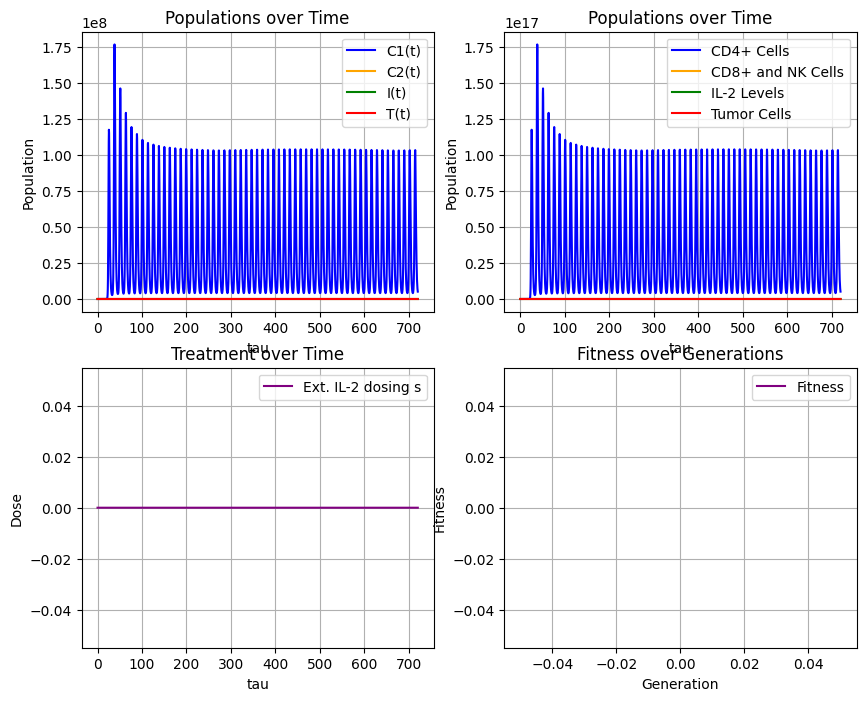

In [3]:
"""
Outputs like: [t, tau, C1, C2, I, T, C1_bar, C2_bar, I_bar, T_bar, s, alpha, Fitness]
"""

# Load Dixon simulation data (Just an example file to check)
t, tau, C1, C2, I, T, C1_bar, C2_bar, I_bar, T_bar, s, alpha, Fitness = load_data('Output_data/dixon_alpha_sweep_no_treatment/simu_data_dixon_alpha_715.72000000000003.csv', 'dixon',)


# Assemble into DataFrame
dixon_alpha_71572 =  pd.DataFrame({
    't': t, 'tau': tau,
    'C1': C1, 'C2': C2, 'I': I, 'T': T,
    'C1_bar': C1_bar, 'C2_bar': C2_bar,
    'I_bar': I_bar, 'T_bar': T_bar,
    's': s, 'alpha': alpha, 'Fitness': Fitness,
    })

# Plot Dixon populations
plot_quad_dixon(dixon_alpha_71572)


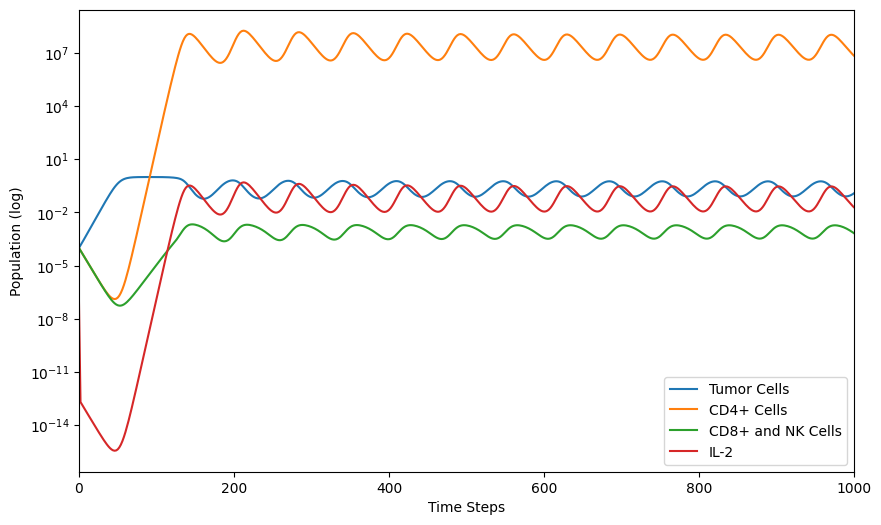

In [4]:
plt.figure(figsize=(10, 6))
plt.plot(t, T, label='Tumor Cells')
plt.plot(t, C1, label='CD4+ Cells')
plt.plot(t, C2, label='CD8+ and NK Cells')
plt.plot(t, I, label='IL-2')
plt.yscale('log')
plt.xlabel('Time Steps')
plt.ylabel('Population (log)')
plt.xlim(0, 1000)
plt.legend()
plt.show()

## Bifurcation analysis

The following code determines and plots these characteristics for each run vs the respective antigenicity value:
1. Amplitude in the last 400 time steps.
2. Maximum T from 400 to 1000.
3. Average T from 500 to 1500.
4. Bifurcation diagram

203 corrected sweep files found.


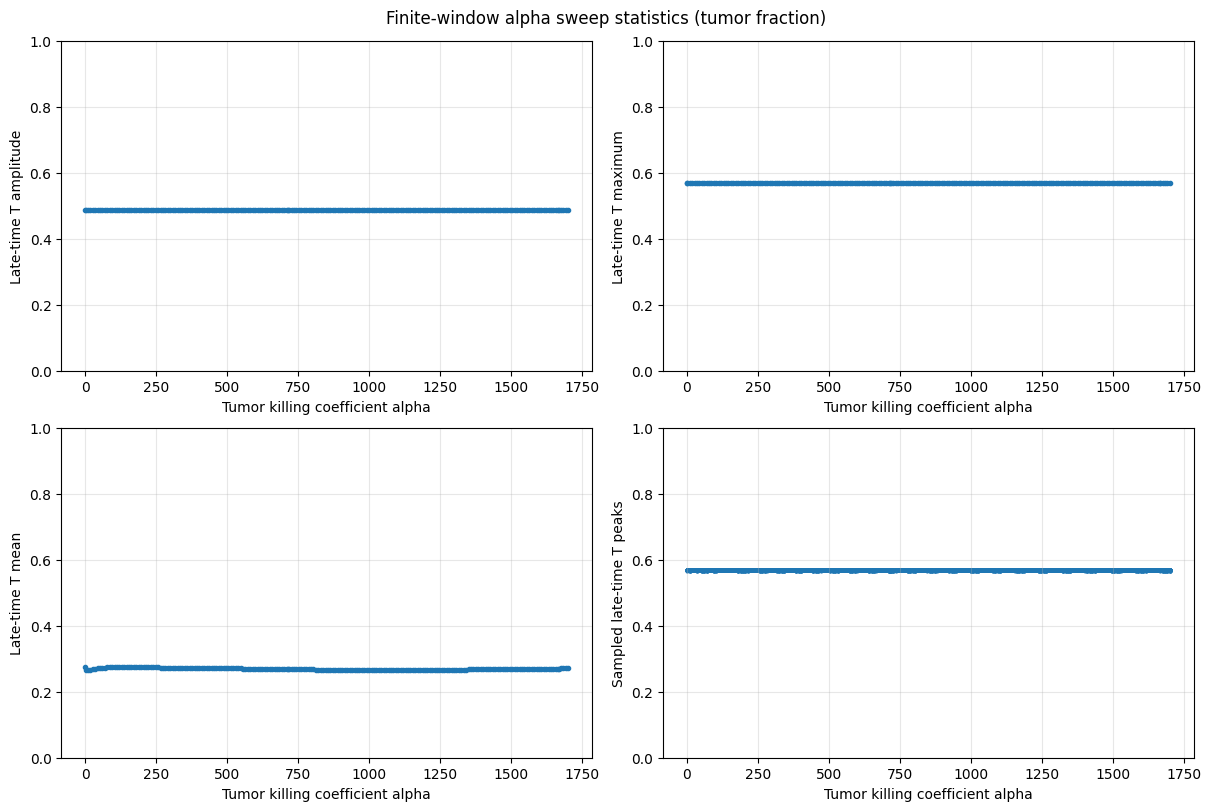

In [5]:
filepath_no_ga, alpha_values_no_ga = sorted_sweep_files(
    'Output_data/dixon_alpha_sweep_no_treatment/simu_data_dixon_alpha_*.csv',
    offset=0.0,
)
print(len(filepath_no_ga), 'corrected sweep files found.')
records = []
peak_alpha, peak_tumor = [], []
for path, alpha_value in zip(filepath_no_ga, alpha_values_no_ga):
    frame = pd.read_csv(path)
    growth_rate = 0.18 # Default growth rate for both models
    if not np.allclose(frame['tau'], growth_rate * frame['t']):
        raise ValueError(f'Inconsistent time scaling in {path}')
    cutoff = frame['t'].iloc[0] + 0.75*(frame['t'].iloc[-1] - frame['t'].iloc[0])
    tail = frame.loc[frame['t'] >= cutoff, 'T'].to_numpy()
    records.append(dict(alpha=alpha_value, amplitude=np.ptp(tail),
                        maximum=np.max(tail), mean=np.mean(tail)))
    peaks, _ = find_peaks(tail)
    peak_alpha.extend([alpha_value] * len(peaks))
    peak_tumor.extend(tail[peaks])
summary = pd.DataFrame(records, columns=['alpha', 'amplitude', 'maximum', 'mean'])

def load_idx1(idx):
    return load_data(filepath_no_ga[idx], 'dixon')

fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
for ax, column in zip(axes.flat, ['amplitude', 'maximum', 'mean']):
    ax.plot(summary['alpha'], summary[column], '.-')
    ax.set(xlabel='Tumor killing coefficient alpha', ylabel=f'Late-time T {column}')
axes[1, 1].scatter(peak_alpha, peak_tumor, s=4)
axes[1, 1].set(xlabel='Tumor killing coefficient alpha', ylabel='Sampled late-time T peaks')
for ax in axes.flat:
    ax.set_ylim(0, 1)  # T is a fraction of carrying capacity.
    ax.grid(alpha=0.3)
fig.suptitle('Finite-window alpha sweep statistics (tumor fraction)')
plt.show()


In [6]:
# create arrays to hold alpha values and corresponding amplitudes
C1_amplitudes = []
C2_amplitudes = []
I_amplitudes = []
T_amplitudes = []

alpha_vals = []

max_vals_C1 = []
ave_vals_C1 = []
max_vals_C2 = []
ave_vals_C2 = []
max_vals_I = []
ave_vals_I = []
max_vals_T = []
ave_vals_T = []

bifur_alpha = []

bifur_C1 = []
bifur_C2 = []
bifur_I = []
bifur_T = []

def bifur_regions(data):
    tail = data[-400:]
    amplitude = tail.max() - tail.min()
    center = data[400:1000]
    max_val = center.max()
    center2 = data[500:1500]
    ave_val = center2.mean()
    return amplitude, max_val, ave_val


# find amplitudes for each file
for idx, f in enumerate(filepath_no_ga):
    df = pd.read_csv(f)
    
    C1 = df["C1"].values
    C2 = df["C2"].values
    I = df["I"].values
    T = df["T"].values

    C1_amp, C1_max_val, C1_ave_val = bifur_regions(C1)
    C2_amp, C2_max_val, C2_ave_val = bifur_regions(C2)
    I_amp, I_max_val, I_ave_val = bifur_regions(I)
    T_amp, T_max_val, T_ave_val = bifur_regions(T)

    alpha_val = alpha_values_no_ga[idx]
    bifur_alpha.extend([alpha_val] * 400)

    bifur_C1.extend(C1[-400:].tolist())
    bifur_C2.extend(C2[-400:].tolist())
    bifur_I.extend(I[-400:].tolist())
    bifur_T.extend(T[-400:].tolist())

    C1_amplitudes.append(C1_amp)
    C2_amplitudes.append(C2_amp)
    I_amplitudes.append(I_amp)
    T_amplitudes.append(T_amp)

    alpha_vals.append(alpha_values_no_ga[idx])
    max_vals_C1.append(C1_max_val)
    ave_vals_C1.append(C1_ave_val)
    max_vals_C2.append(C2_max_val)
    ave_vals_C2.append(C2_ave_val)
    max_vals_I.append(I_max_val)
    ave_vals_I.append(I_ave_val)
    max_vals_T.append(T_max_val)
    ave_vals_T.append(T_ave_val)

alpha_vals_0 = np.array(alpha_vals)

amplitudes_C1_0 = np.array(C1_amplitudes)
amplitudes_C2_0 = np.array(C2_amplitudes)
amplitudes_I_0 = np.array(I_amplitudes)
amplitudes_T_0 = np.array(T_amplitudes)

max_C1_0 = np.array(max_vals_C1)
ave_C1_0 = np.array(ave_vals_C1)

max_C2_0 = np.array(max_vals_C2)
ave_C2_0 = np.array(ave_vals_C2)

max_I_0 = np.array(max_vals_I)
ave_I_0 = np.array(ave_vals_I)

max_T_0 = np.array(max_vals_T)
ave_T_0 = np.array(ave_vals_T)

bifur_alpha = np.array(bifur_alpha)

bifur_C1 = np.array(bifur_C1)
bifur_C2 = np.array(bifur_C2)
bifur_I = np.array(bifur_I)
bifur_T = np.array(bifur_T)



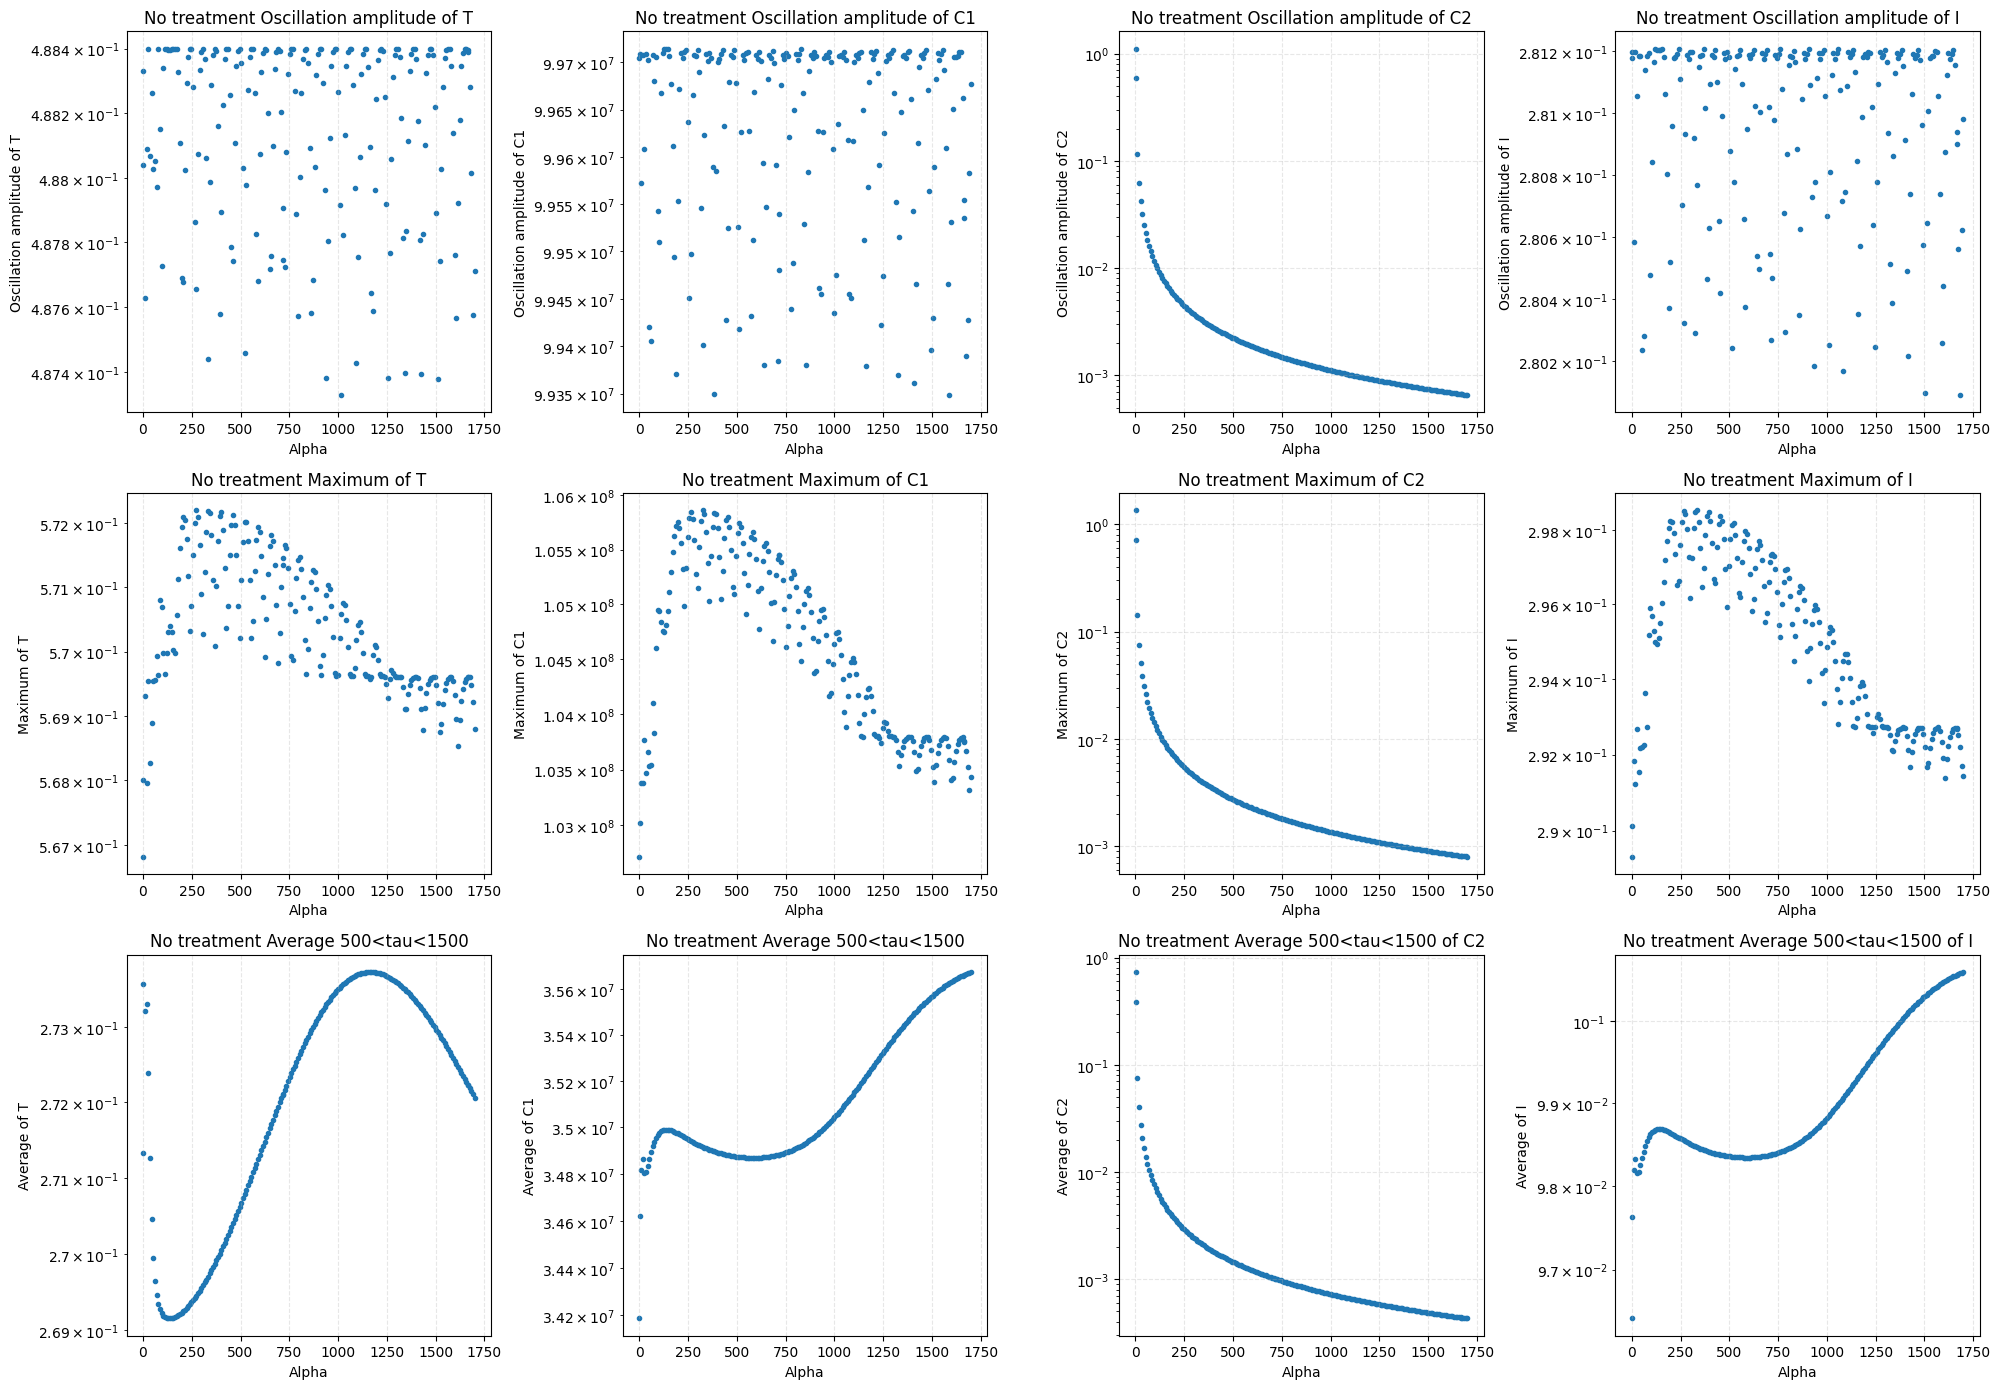

In [7]:
plt.figure(figsize=(20,14))
plt.subplots_adjust(hspace=0.4, wspace=0.4)

plt.subplot(3,4,1)
plt.scatter(alpha_vals_0, amplitudes_T_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Oscillation amplitude of T")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Oscillation amplitude of T")

plt.subplot(3,4,2)
plt.scatter(alpha_vals_0, amplitudes_C1_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Oscillation amplitude of C1")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Oscillation amplitude of C1")

plt.subplot(3,4,3)
plt.scatter(alpha_vals_0, amplitudes_C2_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Oscillation amplitude of C2")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Oscillation amplitude of C2")

plt.subplot(3,4,4)
plt.scatter(alpha_vals_0, amplitudes_I_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Oscillation amplitude of I")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Oscillation amplitude of I")


plt.subplot(3,4,5)
plt.scatter(alpha_vals_0, max_T_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Maximum of T")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Maximum of T")

plt.subplot(3,4,6)
plt.scatter(alpha_vals_0, max_C1_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Maximum of C1")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Maximum of C1")

plt.subplot(3,4,7)
plt.scatter(alpha_vals_0, max_C2_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Maximum of C2")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Maximum of C2")

plt.subplot(3,4,8)
plt.scatter(alpha_vals_0, max_I_0, marker='.', label='No GA, no therapy')
plt.xlabel("Alpha")
plt.ylabel("Maximum of I")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Maximum of I")


plt.subplot(3,4,9)
plt.scatter(alpha_vals_0, ave_T_0, marker='.', label='Average 500<tau<1500')
plt.xlabel("Alpha")
plt.ylabel("Average of T")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Average 500<tau<1500")

plt.subplot(3,4,10)
plt.scatter(alpha_vals_0, ave_C1_0, marker='.', label='Average 500<tau<1500')
plt.xlabel("Alpha")
plt.ylabel("Average of C1")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Average 500<tau<1500")

plt.subplot(3,4,11)
plt.scatter(alpha_vals_0, ave_C2_0, marker='.', label='Average 500<tau<1500')
plt.xlabel("Alpha")
plt.ylabel("Average of C2")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Average 500<tau<1500 of C2")

plt.subplot(3,4,12)
plt.scatter(alpha_vals_0, ave_I_0, marker='.', label='Average 500<tau<1500')
plt.xlabel("Alpha")
plt.ylabel("Average of I")
plt.yscale("log")
plt.grid(alpha=0.3, linestyle='--')
plt.title("No treatment Average 500<tau<1500 of I")


plt.tight_layout()
# plt.savefig("Figures/Dixonanalysis_plot_1.png")
plt.show()

## Tumor peaks across the alpha sweep

The late-time peaks below use Dixon's nondimensional tumor fraction `T`.
All points come from the same no-treatment alpha sweep. This is a finite-time
peak diagram; alpha-dependent sampling and phase differences are not evidence
of a change in equilibrium stability.


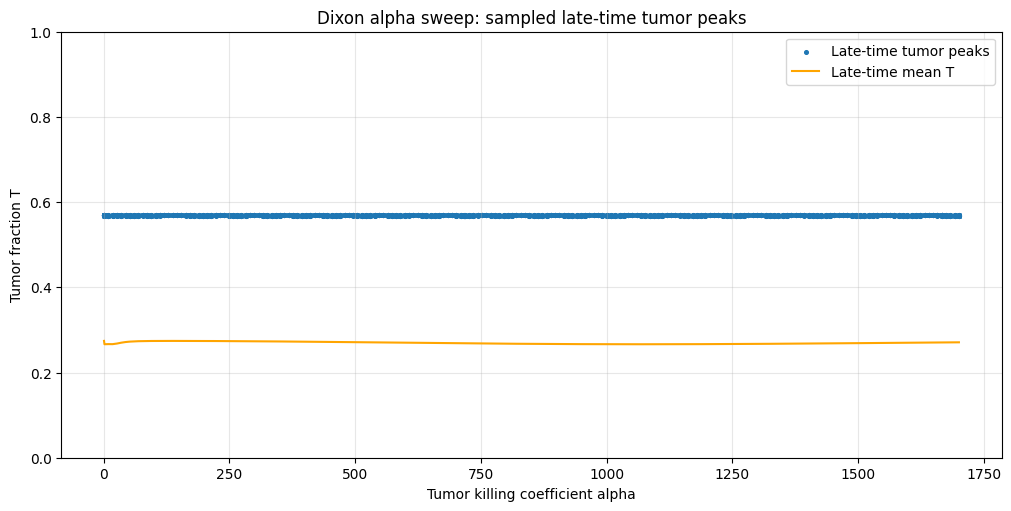

In [8]:
figure_dir = Path('Figures')
figure_dir.mkdir(parents=True, exist_ok=True)
if len(summary):
    fig, ax = plt.subplots(figsize=(10, 5), constrained_layout=True)
    ax.scatter(peak_alpha, peak_tumor, s=7, label='Late-time tumor peaks')
    ax.plot(summary['alpha'], summary['mean'], color='orange', label='Late-time mean T')
    ax.set(xlabel='Tumor killing coefficient alpha', ylabel='Tumor fraction T',
           ylim=(0, 1), title='Dixon alpha sweep: sampled late-time tumor peaks')
    ax.grid(alpha=0.3)
    ax.legend()
    fig.savefig(figure_dir / 'dixon_tumor_peaks_v2.png', dpi=150)
    plt.show()


## Tumor features and FFT

Extract five trajectory statistics and four Fourier spectra per alpha value
from Dixon's `T` column. FFT frequencies use the physical `t` column and are in
cycles/day. Each 500-sample segment has its mean removed. The alpha column
labels the results but is excluded from the features used for dimensionality
reduction and clustering.


In [9]:
from Visualization.data_handling import extract_features, osc_features

feature_names = ['tail_amplitude', 'middle_maximum_1', 'middle_maximum_2',
                 'middle_mean_1', 'middle_mean_2']
features = np.empty((0, 6))
alpha_feature_values = np.array([])
trajectory_features = np.empty((0, 5))
if filepath_no_ga:
    features, alpha_feature_values, tail_amplitudes = extract_features(
        filepath_no_ga, alpha_values_no_ga, value_column='T', offset=0.0,
    )
    trajectory_features = features[:, 1:]
    feature_table = pd.DataFrame(trajectory_features, columns=feature_names)
    feature_table.insert(0, 'alpha', alpha_feature_values)
    y_values, amp_values, freq_values, fft_alpha_values = osc_features(
        filepath_no_ga, alpha_values_no_ga, value_column='T', offset=0.0,
        time_columns=('t',), detrend=True,
    )
    np.testing.assert_allclose(fft_alpha_values, alpha_feature_values)
    print(f'Extracted {len(features)} trajectories with {trajectory_features.shape[1]} features each.')
else:
    print('Generate the Dixon alpha sweep before extracting its features.')


Extracted 203 trajectories with 5 features each.


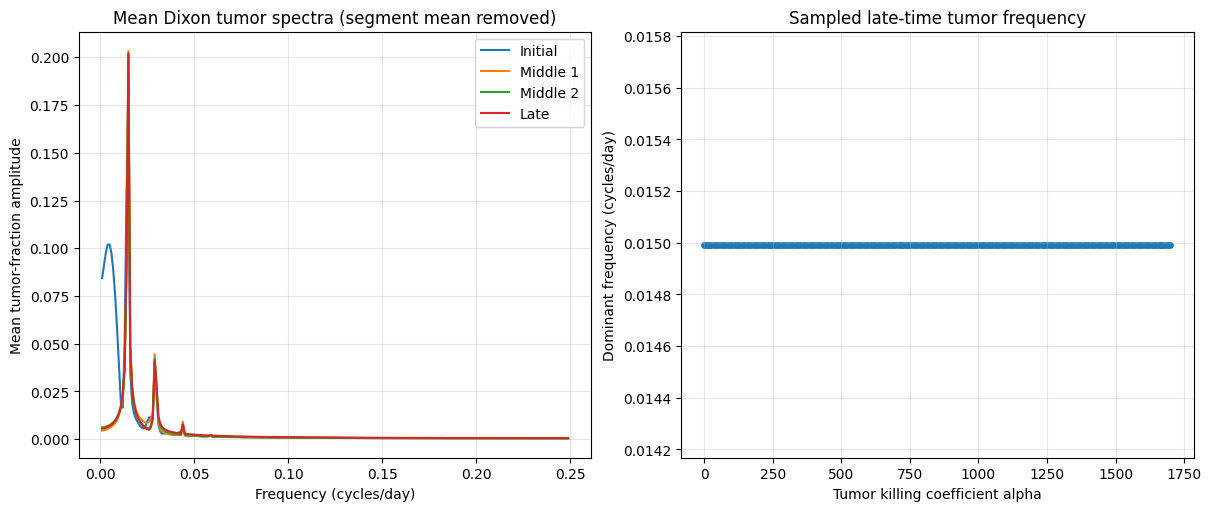

In [10]:
if len(features):
    segment_labels = ['Initial', 'Middle 1', 'Middle 2', 'Late']
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    for label, amplitudes, frequencies in zip(segment_labels, amp_values, freq_values):
        if not np.allclose(frequencies, frequencies[0]):
            raise ValueError('FFT segments must share the same sampling interval to average spectra.')
        positive = frequencies[0] > 0
        # Convert FFT magnitude to a one-sided sinusoidal amplitude.
        spectrum = 2 * amplitudes[:, positive].mean(axis=0) / amplitudes.shape[1]
        axes[0].plot(frequencies[0, positive], spectrum, label=label)
    axes[0].set(xlabel='Frequency (cycles/day)', ylabel='Mean tumor-fraction amplitude',
                title='Mean Dixon tumor spectra (segment mean removed)')
    axes[0].legend()

    late_frequencies = freq_values[-1][0]
    positive = late_frequencies > 0
    late_spectrum = amp_values[-1][:, positive]
    dominant_frequency = late_frequencies[positive][np.argmax(late_spectrum, axis=1)]
    dominant_frequency[np.max(late_spectrum, axis=1) <= 1e-12] = np.nan
    axes[1].scatter(alpha_feature_values, dominant_frequency, s=15)
    axes[1].set(xlabel='Tumor killing coefficient alpha', ylabel='Dominant frequency (cycles/day)',
                title='Sampled late-time tumor frequency')
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.savefig(figure_dir / 'dixon_fft_spectrum_v2.png', dpi=150)
    plt.show()


## Trajectory embedding

Standardize the five tumor trajectory features, then use UMAP to explore their
similarity. If `umap-learn` is unavailable, the plot explicitly uses PCA instead.
Neither embedding is a stability analysis or a biological classification.


In [11]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

embedding = None
if len(trajectory_features):
    scaled_features = StandardScaler().fit_transform(trajectory_features)
    try:
        import umap
    except ImportError:
        umap = None
    if umap is not None and len(scaled_features) >= 4:
        reducer = umap.UMAP(random_state=43, n_jobs=1,
                            n_neighbors=min(15, len(scaled_features)-1))
        embedding = reducer.fit_transform(scaled_features)
        embedding_method = 'UMAP'
    elif len(scaled_features) >= 2:
        embedding = PCA(n_components=2).fit_transform(scaled_features)
        embedding_method = 'PCA'
        print('Using PCA; UMAP requires umap-learn and at least four trajectories.')
    else:
        embedding = np.zeros((1, 2))
        embedding_method = 'Single trajectory'


OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


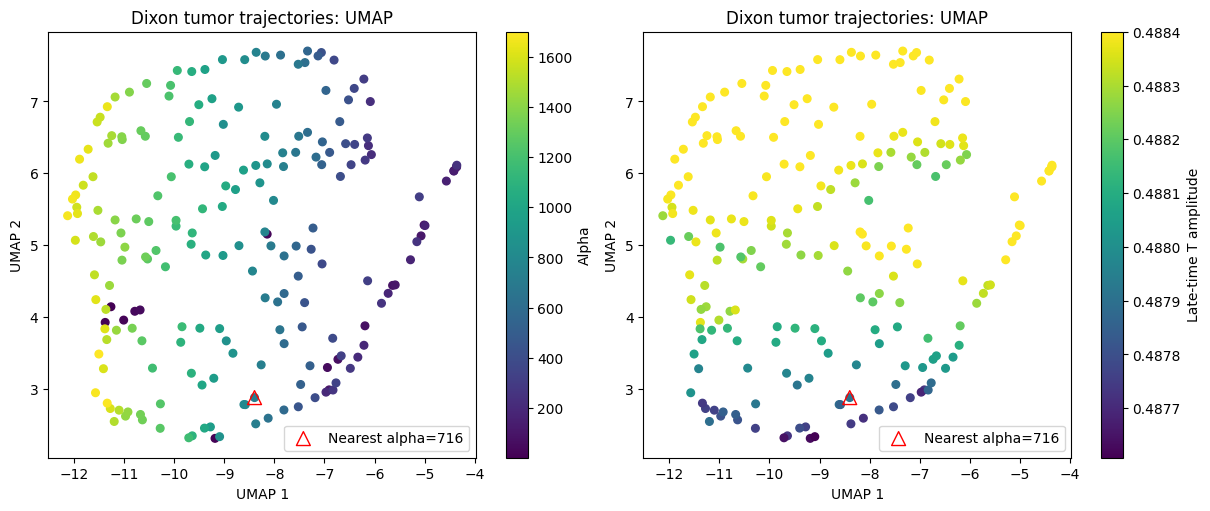

In [12]:
if embedding is not None:
    selected_alpha = 715.72
    selected_idx = int(np.argmin(np.abs(alpha_feature_values - selected_alpha)))
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    for ax, colors, color_label in zip(
        axes, [alpha_feature_values, tail_amplitudes], ['Alpha', 'Late-time T amplitude'],
    ):
        points = ax.scatter(embedding[:, 0], embedding[:, 1], c=colors, cmap='viridis', s=30)
        ax.scatter(*embedding[selected_idx], marker='^', facecolors='none', edgecolors='red',
                   s=100, label=f'Nearest alpha={alpha_feature_values[selected_idx]:.3g}')
        ax.set(xlabel=f'{embedding_method} 1', ylabel=f'{embedding_method} 2',
               title=f'Dixon tumor trajectories: {embedding_method}')
        fig.colorbar(points, ax=ax, label=color_label)
        ax.legend()
    fig.savefig(figure_dir / 'dixon_embedding_v2.png', dpi=150)
    plt.show()


## Explore trajectory clusters

K-means uses the standardized trajectory features, not the embedding coordinates
or alpha labels. The groups are descriptive and depend on the selected features
and requested cluster count.


         trajectories  alpha_min    alpha_max  mean_tumor_amplitude
cluster                                                            
0                  50   1.000000  1700.000000              0.488267
1                  71  26.613065  1204.814070              0.488308
2                  40  77.839196  1648.773869              0.488399
3                  42   9.537688  1512.170854              0.487888


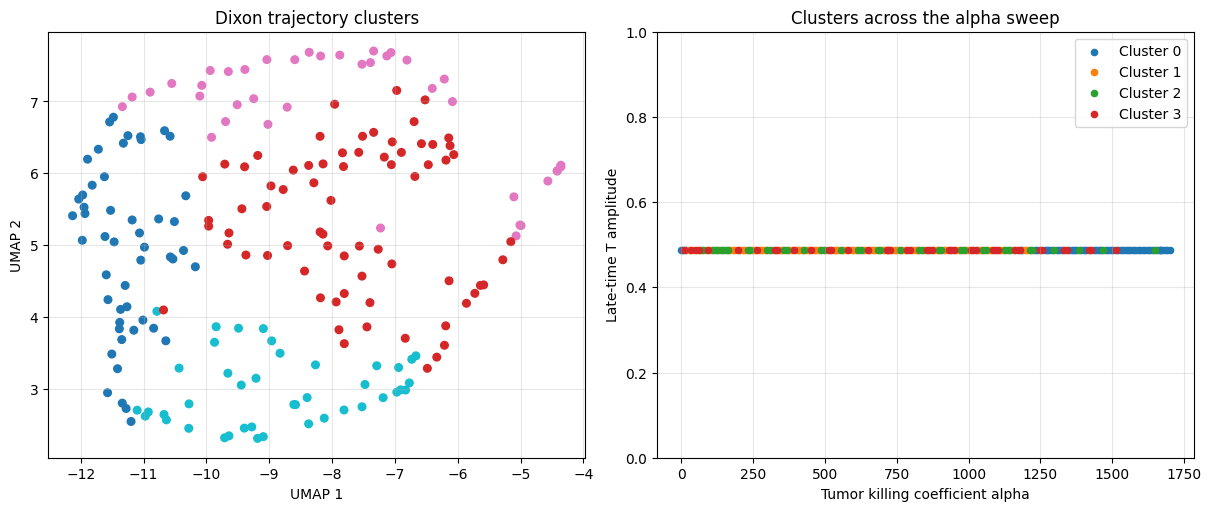

In [13]:
from sklearn.cluster import KMeans

if embedding is not None:
    n_clusters = min(4, len(np.unique(scaled_features, axis=0)))
    cluster_labels = KMeans(n_clusters=n_clusters, random_state=0, n_init=10).fit_predict(scaled_features)
    clustered_features = feature_table.assign(cluster=cluster_labels)
    print(clustered_features.groupby('cluster').agg(
        trajectories=('alpha', 'size'), alpha_min=('alpha', 'min'), alpha_max=('alpha', 'max'),
        mean_tumor_amplitude=('tail_amplitude', 'mean'),
    ))
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
    axes[0].scatter(embedding[:, 0], embedding[:, 1], c=cluster_labels, cmap='tab10', s=30)
    axes[0].set(xlabel=f'{embedding_method} 1', ylabel=f'{embedding_method} 2',
                title='Dixon trajectory clusters')
    for label in range(n_clusters):
        mask = cluster_labels == label
        axes[1].scatter(alpha_feature_values[mask], tail_amplitudes[mask], s=20,
                        label=f'Cluster {label}')
    axes[1].set(xlabel='Tumor killing coefficient alpha', ylabel='Late-time T amplitude',
                ylim=(0, 1), title='Clusters across the alpha sweep')
    axes[1].legend()
    for ax in axes:
        ax.grid(alpha=0.3)
    fig.savefig(figure_dir / 'dixon_clusters_v2.png', dpi=150)
    plt.show()
